# Notebook 08 — Diagnostics Économétriques & Sélection de Modèle (2000–2025)

## Batterie de Tests d'Hypothèses sur les Résidus
Pour valider nos inférences économétriques, nous soumettons nos modèles principaux (**M1 - Niveau Log-Log**, **M3 - Croissance Contrôlée**, **M7 - ARDL Parcimonieux**) aux tests stochastiques standards :
* **Durbin-Watson (DW)** : Absence d'autocorrélation d'ordre 1 ($DW \approx 2$).
* **Breusch-Pagan (BP)** : Homoscédasticité des résidus ($H_0 : \text{Var}(\varepsilon_t) = \sigma^2$).
* **Jarque-Bera (JB)** : Normalité des résidus ($H_0 : \varepsilon \sim \mathcal{N}(0, \sigma^2)$).
* **Ramsey RESET** : Absence de mauvaise spécification / de variables omises non-linéaires.

In [1]:
# ==============================================================================
# 1. TESTS DE DIAGNOSTIC ÉCONOMÉTRIQUE AUTOMATISÉS
# ==============================================================================
from pathlib import Path
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset

# Configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.5f' % x)

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
tables_dir = project_root / "outputs" / "tables"
figures_dir = project_root / "outputs" / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Chargement du jeu de données audité
df = pd.read_csv(project_root / "data" / "intermediate" / "ntl_processed" / "niger_ntl_audited_2000_2025.csv")

# Transformations Logarithmiques et Différences
df['ln_gdp'] = np.log(df['gdp_real'])
df['ln_ntl'] = np.log(df['ntl_sum_adj'])
df['d_ln_gdp'] = df['ln_gdp'].diff()
df['d_ln_ntl'] = df['ln_ntl'].diff()
df['d_ln_gdp_lag1'] = df['d_ln_gdp'].shift(1)
df['d_ln_ntl_lag1'] = df['d_ln_ntl'].shift(1)

# Estimation des 3 modèles de référence
m1 = smf.ols('ln_gdp ~ ln_ntl + dummy_viirs', data=df).fit()
m3 = smf.ols('d_ln_gdp ~ d_ln_ntl + dummy_2017 + dummy_trans_2012', data=df.dropna(subset=['d_ln_gdp', 'd_ln_ntl'])).fit()

df_dyn = df.dropna(subset=['d_ln_gdp', 'd_ln_ntl', 'd_ln_gdp_lag1', 'd_ln_ntl_lag1']).copy()
m7 = smf.ols('d_ln_gdp ~ d_ln_gdp_lag1 + d_ln_ntl + d_ln_ntl_lag1 + dummy_2017', data=df_dyn).fit()

def run_full_diagnostics(model, model_name):
    """Calcule la batterie de diagnostics sur un modèle estimé."""
    resids = model.resid
    
    # 1. Durbin-Watson
    dw_stat = durbin_watson(resids)
    
    # 2. Jarque-Bera (Normalité)
    jb_stat, jb_pval, _, _ = jarque_bera(resids)
    
    # 3. Breusch-Pagan (Hétéroscédasticité)
    bp_stat, bp_pval, _, _ = het_breuschpagan(resids, model.model.exog)
    
    # 4. Ramsey RESET (Spécification)
    try:
        reset_res = linear_reset(model, power=2, use_f=True)
        reset_pval = reset_res.pvalue
    except Exception:
        reset_pval = np.nan

    return {
        'Modèle': model_name,
        'Durbin-Watson': dw_stat,
        'Autocorrélation': 'Présente' if (dw_stat < 1.3 or dw_stat > 2.7) else 'Absente',
        'Breusch-Pagan (p-val)': bp_pval,
        'Hétéroscédasticité': 'Présente' if bp_pval < 0.05 else 'Absente',
        'Jarque-Bera (p-val)': jb_pval,
        'Normalité Résidus': 'Non-Normaux' if jb_pval < 0.05 else 'Normaux',
        'Ramsey RESET (p-val)': reset_pval
    }

diag_results = [
    run_full_diagnostics(m1, 'Modèle 1 (Log-Log Niveau)'),
    run_full_diagnostics(m3, 'Modèle 3 (Croissance Contrôlée)'),
    run_full_diagnostics(m7, 'Modèle 7 (ARDL 1,1)')
]

df_diag_summary = pd.DataFrame(diag_results)

print("[✓] Diagnostics économétriques exécutés avec succès.")

[✓] Diagnostics économétriques exécutés avec succès.


## Section 2 : Validation des Diagnostics Économétriques

Nous vérifions si nos modèles respectent les conditions de Gauss-Markov et d'inférence valide :
1. **Durbin-Watson** : Absence d'autocorrélation de premier ordre si $DW \approx 2$.
2. **Breusch-Pagan** : Vérification de l'homoscédasticité ($p\text{-value} > 0.05$).
3. **Jarque-Bera** : Vérification de la normalité de la distribution des résidus ($p\text{-value} > 0.05$).
4. **Ramsey RESET** : Absence de mauvaise spécification fonctionnelle ($p\text{-value} > 0.05$).

In [2]:
# ==============================================================================
# 2. TABLEAU RÉCAPITULATIF DES DIAGNOSTICS & TEST VIF
# ==============================================================================
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("=======================================================================================")
print(" TABLEAU SYNTHÉTIQUE DES DIAGNOSTICS ÉCONOMÉTRIQUES")
print("=======================================================================================")
print(df_diag_summary[['Modèle', 'Durbin-Watson', 'Autocorrélation', 'Breusch-Pagan (p-val)', 'Jarque-Bera (p-val)', 'Normalité Résidus', 'Ramsey RESET (p-val)']])

# Calcul des VIF sur le Modèle 3 (Croissance contrôlée)
X_m3 = m3.model.exog
vif_m3 = pd.DataFrame({
    'Variable': m3.model.exog_names,
    'VIF': [variance_inflation_factor(X_m3, i) for i in range(X_m3.shape[1])]
})

print("\n--- Facteurs d'Inflation de la Variance (VIF) — Modèle 3 ---")
print(vif_m3)

# Exportation des tableaux en CSV
tables_dir = project_root / "outputs" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

out_diag_path = tables_dir / "08_diagnostics_summary.csv"
out_vif_path = tables_dir / "08_vif_summary.csv"

df_diag_summary.to_csv(out_diag_path, index=False)
vif_m3.to_csv(out_vif_path, index=False)

print(f"\n[✓] Tableau des diagnostics exporté vers : {out_diag_path}")
print(f"[✓] Tableau des VIF exporté vers : {out_vif_path}")

 TABLEAU SYNTHÉTIQUE DES DIAGNOSTICS ÉCONOMÉTRIQUES
                            Modèle  Durbin-Watson Autocorrélation  \
0        Modèle 1 (Log-Log Niveau)        1.26597        Présente   
1  Modèle 3 (Croissance Contrôlée)        2.80088        Présente   
2              Modèle 7 (ARDL 1,1)        1.97220         Absente   

   Breusch-Pagan (p-val)  Jarque-Bera (p-val) Normalité Résidus  \
0                0.30489              0.84332           Normaux   
1                0.67887              0.92209           Normaux   
2                0.39471              0.37915           Normaux   

   Ramsey RESET (p-val)  
0               0.99762  
1               0.95512  
2               0.27898  

--- Facteurs d'Inflation de la Variance (VIF) — Modèle 3 ---
           Variable     VIF
0         Intercept 1.00000
1          d_ln_ntl 2.57774
2        dummy_2017 2.57858
3  dummy_trans_2012 1.00180

[✓] Tableau des diagnostics exporté vers : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\o

<>:13: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:13: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_17840\2475322169.py:13: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  ax1.set_xlabel('Résidus ($\hat{\epsilon}_t$)')


[✓] Figure de diagnostic des résidus sauvegardée dans : c:\Niger & Big Data\NTL et PIB Niger\niger_ntl_gdp\outputs\figures\08_residuals_normality_qqplot.png


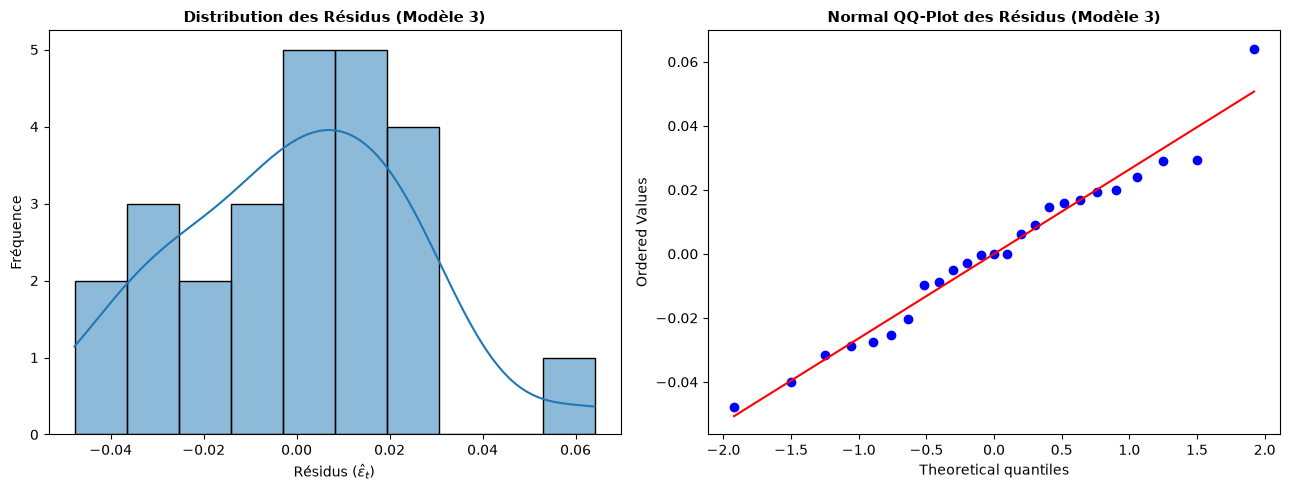

In [3]:
# ==============================================================================
# 3. VISUALISATION DE LA NORMALITÉ ET DE LA DISTRIBUTION DES RÉSIDUS (M3)
# ==============================================================================
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Histogramme et Densité Kernel
sns.histplot(m3.resid, kde=True, ax=ax1, color='#1f77b4', bins=10)
ax1.set_title('Distribution des Résidus (Modèle 3)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Résidus ($\hat{\epsilon}_t$)')
ax1.set_ylabel('Fréquence')

# QQ-Plot
stats.probplot(m3.resid, dist="norm", plot=ax2)
ax2.set_title('Normal QQ-Plot des Résidus (Modèle 3)', fontsize=11, fontweight='bold')

plt.tight_layout()

# SAUVEGARDE DE LA FIGURE
figures_dir = project_root / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
fig_diag_png = figures_dir / "08_residuals_normality_qqplot.png"
fig_diag_pdf = figures_dir / "08_residuals_normality_qqplot.pdf"

plt.savefig(fig_diag_png, dpi=300, bbox_inches='tight')
plt.savefig(fig_diag_pdf, bbox_inches='tight')

print(f"[✓] Figure de diagnostic des résidus sauvegardée dans : {fig_diag_png}")
plt.show()